# Probabilistic PCA: from EM to a Linear VAE

This is the **bridge notebook** for Lecture 17. Lecture 16 fitted a mixture
by EM, where the hidden variable took one of $K$ values. Here the hidden
variable is a continuous code $z\in\mathbb R^r$, and the model is the
simplest one in which the EM of Lecture 16 still works exactly:
**probabilistic PCA** (Tipping and Bishop, 1999),

$$z\sim\mathcal N(0,I_r),\qquad x\mid z\sim\mathcal N(Wz+\mu,\;\sigma^2I_d).$$

We will:

1. build the model on a two-dimensional toy problem and check that the first
   principal direction of the data lands on $\mathrm{col}(W)$;
2. check the marginal covariance $WW^\top+\sigma^2I$ and its eigenvalues;
3. verify the closed-form posterior $p(z\mid x)$ of Appendix A.1 against
   ordinary Gaussian conditioning, and see the shrinkage of Appendix A.3;
4. run EM (Appendix A.2) on 10,000 MNIST images and watch the likelihood
   rise and the fitted subspace rotate onto the PCA subspace;
5. look at what the fitted linear model does to images: reconstructions and
   samples;
6. train the same model as a **linear VAE**, by stochastic gradient ascent on
   the ELBO with a linear Gaussian encoder, and measure the gap between the
   ELBO and the exact log likelihood.

The last step is the slide *A Linear $q_\phi$ Gives PPCA*: the variational
family contains the true posterior, so the gap closes. The companion
notebook `vae-mnist` replaces the linear decoder by a network, where that
closed form is lost.

**Running the notebook.** Everything runs on a laptop CPU in under a minute (about 30 seconds on
an Apple M4 Pro).
MNIST (11 MB) is downloaded into a `mnist/` folder beside the notebook on
first use. Reading: Bishop, *Pattern Recognition and Machine Learning*,
§12.2; Tipping and Bishop (1999), *Probabilistic Principal Component
Analysis*, JRSS-B 61(3).

The first cell imports the libraries, fixes the seed, and loads MNIST
(the same loader as Lecture 11). We keep a random subset of 10,000 training
images, scaled to $[0,1]$, and the 10,000 test images for held-out checks.
The labels are loaded only to caption pictures; no model below uses them.

In [1]:
import gzip
import struct
import time
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn

NOTEBOOK_START = time.time()
SEED = 26520
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)

MNIST_URL = 'https://ossci-datasets.s3.amazonaws.com/mnist/'

def load_mnist(folder='mnist'):
    """Download the four MNIST files once, then read them into NumPy arrays."""
    folder = Path(folder)
    folder.mkdir(exist_ok=True)
    splits = {}
    for split, prefix in [('train', 'train'), ('test', 't10k')]:
        arrays = []
        for kind in ['images-idx3-ubyte', 'labels-idx1-ubyte']:
            name = f'{prefix}-{kind}.gz'
            if not (folder / name).exists():
                urllib.request.urlretrieve(MNIST_URL + name, folder / name)
            with gzip.open(folder / name, 'rb') as handle:
                _, count = struct.unpack('>II', handle.read(8))
                if 'images' in kind:
                    rows, cols = struct.unpack('>II', handle.read(8))
                    data = np.frombuffer(handle.read(), np.uint8).reshape(count, rows * cols)
                else:
                    data = np.frombuffer(handle.read(), np.uint8)
            arrays.append(data)
        splits[split] = (arrays[0].astype(np.float64) / 255, arrays[1].astype(np.int64))
    return splits

splits = load_mnist()
keep = rng.choice(60_000, 10_000, replace=False)
X, labels = splits['train'][0][keep], splits['train'][1][keep]
X_test, labels_test = splits['test']
n, d = X.shape
print('training subset:', X.shape, ' test images:', X_test.shape)
assert (n, d) == (10_000, 784)

training subset: (10000, 784)  test images: (10000, 784)


## 1. The generative story in two dimensions

The model says $x=\mu+Wz+\epsilon$: a **signal** $Wz$ that can only land in
the column space of $W$, plus isotropic **noise** $\epsilon$. With $d=2$ and
$r=1$, $W$ is a single column and the signal lies on a line. This is the
construction behind the slide *Building an Observation in Two Steps*: 260
draws, $\|W\|=1.7$, noise standard deviation $0.32$, $\mu=0$, seed 26520.

The cell draws the signal and the observations, then fits ordinary PCA (the
top right-singular vector of the centred data) and reports the angle between
that direction and $\mathrm{col}(W)$. Look at the third panel: the dashed
line is what PCA finds from the cloud alone, without knowing $W$.

angle between the first principal direction and col(W): 0.02 degrees


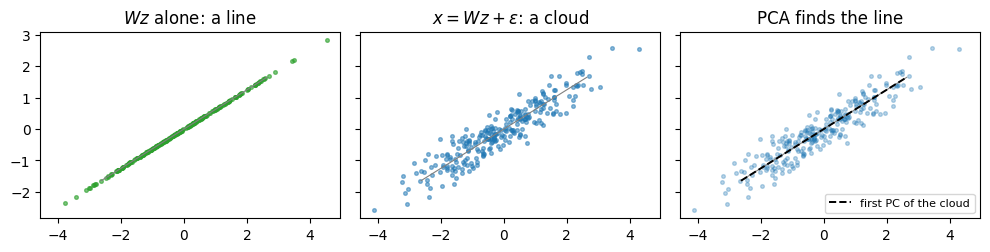

In [2]:
toy_rng = np.random.default_rng(SEED)
direction = np.array([.85, .53]); direction /= np.linalg.norm(direction)
W_toy = 1.7 * direction[:, None]                         # d x r = 2 x 1
noise_sd = .32
z_toy = toy_rng.normal(size=260)
signal = z_toy[:, None] * W_toy[:, 0]                     # W z, on a line
x_toy = signal + toy_rng.normal(scale=noise_sd, size=(260, 2))

centered = x_toy - x_toy.mean(axis=0)
first_pc = np.linalg.svd(centered, full_matrices=False)[2][0]
angle_toy = np.degrees(np.arccos(abs(first_pc @ direction)))
print(f'angle between the first principal direction and col(W): {angle_toy:.2f} degrees')

span = 3.1
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), sharex=True, sharey=True)
for ax in axes:
    ax.plot([-span * direction[0], span * direction[0]], [-span * direction[1], span * direction[1]],
            color='gray', lw=.8)
axes[0].scatter(*signal.T, s=7, color='tab:green', alpha=.6); axes[0].set_title('$Wz$ alone: a line')
axes[1].scatter(*x_toy.T, s=7, alpha=.5); axes[1].set_title('$x=Wz+\\epsilon$: a cloud')
axes[2].scatter(*x_toy.T, s=7, alpha=.3)
axes[2].plot([-span * first_pc[0], span * first_pc[0]], [-span * first_pc[1], span * first_pc[1]],
             'k--', lw=1.4, label='first PC of the cloud')
axes[2].legend(loc='lower right', fontsize=8); axes[2].set_title('PCA finds the line')
for ax in axes:
    ax.set_aspect('equal')
plt.tight_layout(); plt.show()
assert angle_toy < 0.5

The first principal direction of the noisy cloud is within 0.02
degrees of $\mathrm{col}(W)$, well inside the $0.5^\circ$ quoted on the slide. PCA was never
told that a line generated the data; it recovered the line from the shape
of the cloud, because the noise spreads the points equally in every
direction and only the signal stretches them along $W$. The next two
sections say why this is exact in the population.

## 2. The marginal covariance and its eigenvalues

Integrating out $z$ gives $x\sim\mathcal N(\mu,\,WW^\top+\sigma^2I_d)$. If
$W=[a_1u_1,\dots,a_ru_r]$ has orthogonal columns, the covariance has
eigenvalue $a_j^2+\sigma^2$ along each $u_j$ and $\sigma^2$ in every direction
orthogonal to $\mathrm{col}(W)$.

For the toy model, $a_1=1.7$ and $\sigma^2=0.32^2$, so the two eigenvalues
should be $1.7^2+0.1024=2.9924$ and $0.1024$. The cell draws 200,000
observations from the same model and compares the sample covariance with
$WW^\top+\sigma^2I$. Look at whether the two eigenvalues match and whether
the top eigenvector is $\pm$ the unit vector along $W$.

In [3]:
big_z = toy_rng.normal(size=200_000)
big_x = big_z[:, None] * W_toy[:, 0] + toy_rng.normal(scale=noise_sd, size=(200_000, 2))
sample_cov = np.cov(big_x.T)
model_cov = W_toy @ W_toy.T + noise_sd ** 2 * np.eye(2)
values, vectors = np.linalg.eigh(sample_cov)
print('sample covariance:\n', np.round(sample_cov, 4))
print('W W^T + sigma^2 I:\n', np.round(model_cov, 4))
print('sample eigenvalues :', np.round(values[::-1], 4))
print('predicted          :', [round(1.7 ** 2 + noise_sd ** 2, 4), round(noise_sd ** 2, 4)])
print('|cos| between top eigenvector and W:', round(abs(vectors[:, -1] @ direction), 6))
assert np.allclose(sample_cov, model_cov, atol=.03)
assert abs(values[-1] - (1.7 ** 2 + noise_sd ** 2)) < .03 and abs(values[0] - noise_sd ** 2) < .005

sample covariance:
 [[2.1822 1.2967]
 [1.2967 0.9103]]
W W^T + sigma^2 I:
 [[2.1833 1.2975]
 [1.2975 0.9115]]
sample eigenvalues : [2.9905 0.1019]
predicted          : [2.9924, 0.1024]
|cos| between top eigenvector and W: 1.0


With 200,000 draws the sample covariance agrees with
$WW^\top+\sigma^2I$ to the second decimal, the eigenvalues come out as
2.9905 and 0.1019, against the predicted 2.9924 and 0.1024, and the top eigenvector is
aligned with $W$ to six digits. So the top-$r$ eigenvectors of
$\operatorname{Cov}(x)$ span $\mathrm{col}(W)$ and the smallest eigenvalue
reveals $\sigma^2$: everything PCA computes is a function of this one
covariance matrix.

## 3. The posterior of the code (Appendices A.1 and A.3)

Completing the square in $\log p(z)+\log p(x\mid z)$ gives, with
$M=W^\top W+\sigma^2I_r$,

$$p(z\mid x)=\mathcal N\bigl(M^{-1}W^\top(x-\mu),\;\sigma^2M^{-1}\bigr).$$

There is a second route to the same answer that uses nothing specific to
PPCA. The pair $(z,x)$ is jointly Gaussian with
$\operatorname{Cov}(z)=I$, $\operatorname{Cov}(z,x)=W^\top$ and
$\operatorname{Cov}(x)=C=WW^\top+\sigma^2I$, and the textbook conditioning
formula gives mean $W^\top C^{-1}(x-\mu)$ and covariance $I-W^\top C^{-1}W$.
The first route inverts an $r\times r$ matrix; the second inverts a
$d\times d$ one.

The cell draws a random $W$ with $d=6$, $r=2$, $\sigma^2=0.5$, computes the
posterior both ways for one observation, and prints the largest
discrepancy. Look also at what the posterior covariance depends on.

In [4]:
small_rng = np.random.default_rng(SEED + 1)
d_s, r_s, s2_s = 6, 2, .5
W_s = small_rng.normal(size=(d_s, r_s)); mu_s = small_rng.normal(size=d_s)
x_s = small_rng.normal(size=d_s) * 2

M_s = W_s.T @ W_s + s2_s * np.eye(r_s)
mean_A1 = np.linalg.solve(M_s, W_s.T @ (x_s - mu_s))
cov_A1 = s2_s * np.linalg.inv(M_s)

C_s = W_s @ W_s.T + s2_s * np.eye(d_s)                   # d x d covariance of x
mean_joint = W_s.T @ np.linalg.solve(C_s, x_s - mu_s)
cov_joint = np.eye(r_s) - W_s.T @ np.linalg.solve(C_s, W_s)

print('posterior mean, Appendix A.1:', np.round(mean_A1, 6))
print('posterior mean, conditioning:', np.round(mean_joint, 6))
print('posterior cov,  Appendix A.1:\n', np.round(cov_A1, 6))
print('largest discrepancy:', max(abs(mean_A1 - mean_joint).max(), abs(cov_A1 - cov_joint).max()))
assert np.allclose(mean_A1, mean_joint) and np.allclose(cov_A1, cov_joint)

posterior mean, Appendix A.1: [-3.438754 -0.325305]
posterior mean, conditioning: [-3.438754 -0.325305]
posterior cov,  Appendix A.1:
 [[0.292107 0.039904]
 [0.039904 0.051235]]
largest discrepancy: 1.7763568394002505e-15


Both routes give the same mean and covariance up to rounding error
(the largest discrepancy is $2\times10^{-15}$). Notice that $x$ appears only in the mean: the posterior
covariance $S=\sigma^2M^{-1}$ is built from $W$ and $\sigma^2$ alone, so
**every observation shares the same $S$**. The E-step therefore computes one
$r\times r$ matrix $S$ and one mean $m_i$ per image.

**Shrinkage.** If the columns of $W$ are orthogonal, $W=[a_1u_1,\dots]$, then
$M$ is diagonal and coordinate $j$ of the posterior mean is
$\frac{a_j}{a_j^2+\sigma^2}\,u_j^\top(x-\mu)$: the PCA score along $u_j$,
multiplied by a factor. As $\sigma^2\to0$ the factor becomes $1/a_j$ and the
posterior mean is just the standardized PCA score. For positive $\sigma^2$
it is a little smaller, because the model attributes part of every score to
noise. We will see the size of this factor on MNIST in Section 5.

## 4. EM on MNIST

The parameter is $\theta=(W,\mu,\sigma^2)$. The maximum-likelihood $\mu$ is
the sample mean $\bar x$ whatever $W$ and $\sigma^2$ are, so we centre the
images once and iterate on $W$ and $\sigma^2$. One EM cycle:

* **E-step.** $M=W^\top W+\sigma^2I$, $\;m_i=M^{-1}W^\top(x_i-\bar x)$,
  $\;S=\sigma^2M^{-1}$, $\;\mathbb E[z_iz_i^\top\mid x_i]=m_im_i^\top+S$.
* **M-step (Appendix A.2).**
  $W^{\rm new}=\bigl[\sum_i(x_i-\bar x)m_i^\top\bigr]\bigl[\sum_i(m_im_i^\top+S)\bigr]^{-1}$,
  and $(\sigma^2)^{\rm new}$ is the average expected squared residual
  $\frac1{nd}\sum_i\mathbb E\bigl[\|x_i-\bar x-W^{\rm new}z_i\|^2\mid x_i\bigr]$.

To check EM we need the observed log likelihood, which is a Gaussian
log density with covariance $C=WW^\top+\sigma^2I_{784}$. Two identities
avoid ever forming the $784\times784$ inverse:
$\log\det C=(d-r)\log\sigma^2+\log\det M$ and
$C^{-1}=\sigma^{-2}\bigl(I-WM^{-1}W^\top\bigr)$. With $\widehat\Sigma$ the
sample covariance, the average log likelihood per image is
$-\tfrac12\bigl[d\log2\pi+\log\det C+\operatorname{tr}(C^{-1}\widehat\Sigma)\bigr]$.

The cell centres the data, computes $\widehat\Sigma$ and its eigenvectors
(the PCA answer we will compare against), and defines the E-step, the
M-step, the log likelihood, and the largest **principal angle** between two
subspaces: $0^\circ$ means the subspaces coincide, $90^\circ$ means some
direction in one is orthogonal to all of the other.

In [5]:
mu_hat = X.mean(axis=0)
Xc = X - mu_hat
Sigma_hat = Xc.T @ Xc / n
eigenvalues, eigenvectors = np.linalg.eigh(Sigma_hat)
eigenvalues, eigenvectors = eigenvalues[::-1], eigenvectors[:, ::-1]      # largest first
print(f'total variance {eigenvalues.sum():.2f}; top five eigenvalues', np.round(eigenvalues[:5], 3))
print('pixels that are zero in every image:', int((X.std(axis=0) == 0).sum()))

def e_step(W, sigma2):
    r = W.shape[1]
    M = W.T @ W + sigma2 * np.eye(r)
    M_inv = np.linalg.inv(M)
    m = Xc @ W @ M_inv                 # row i is m_i = M^{-1} W^T (x_i - mean)
    S = sigma2 * M_inv                 # shared by every image
    return m, S

def m_step(m, S):
    Ezz = m.T @ m + n * S                               # sum_i (m_i m_i^T + S)
    W = (Xc.T @ m) @ np.linalg.inv(Ezz)
    # E||x_i - W z_i||^2 = ||x_i||^2 - 2 m_i^T W^T x_i + tr(E[z z^T] W^T W)
    sigma2 = (np.sum(Xc ** 2) - 2 * np.sum((Xc @ W) * m) + np.trace(Ezz @ W.T @ W)) / (n * d)
    return W, sigma2

def log_likelihood(W, sigma2, Sigma=Sigma_hat):
    """Average Gaussian log density per image under N(mean, W W^T + sigma2 I)."""
    r = W.shape[1]
    M = W.T @ W + sigma2 * np.eye(r)
    log_det = (d - r) * np.log(sigma2) + np.linalg.slogdet(M)[1]
    trace = (np.trace(Sigma) - np.trace(np.linalg.solve(M, W.T @ Sigma @ W))) / sigma2
    return -.5 * (d * np.log(2 * np.pi) + log_det + trace)

def largest_angle(A, B):
    """Largest principal angle in degrees between col(A) and col(B)."""
    QA, QB = np.linalg.qr(A)[0], np.linalg.qr(B)[0]
    cosines = np.linalg.svd(QA.T @ QB, compute_uv=False)
    return np.degrees(np.arccos(np.clip(cosines.min(), -1, 1)))

total variance 52.70; top five eigenvalues [5.076 3.712 3.241 2.88  2.589]
pixels that are zero in every image: 115


The top eigenvalue is about 5.1 out of a total variance of 52.7: no
single direction dominates MNIST, which is why a two-dimensional linear
code will be a crude summary. The 115 pixels that are zero in every image
(mostly along the border) carry no variance at all.

Now run EM with $r=2$ from a random start. We start $W$ small (entries
$\mathcal N(0,1/d)$, so each column has length about 1) and $\sigma^2$ at the
average pixel variance; the *Try It* section explains why a large start is
slow. At every iteration the cell records the log likelihood, the largest
principal angle between $\mathrm{col}(W)$ and the top two eigenvectors, and
$\sigma^2$. Look at how fast the angle falls compared with the likelihood.

In [6]:
def run_em(r, iterations, seed=SEED):
    init = np.random.default_rng(seed)
    W = init.normal(scale=1 / np.sqrt(d), size=(d, r))
    sigma2 = np.trace(Sigma_hat) / d
    trace = []
    for t in range(iterations + 1):
        trace.append({'iteration': t, 'log likelihood': log_likelihood(W, sigma2),
                      'angle': largest_angle(W, eigenvectors[:, :r]), 'sigma2': sigma2})
        if t < iterations:
            m, S = e_step(W, sigma2)
            W, sigma2 = m_step(m, S)
    return W, sigma2, pd.DataFrame(trace)

start = time.time()
W2, sigma2_2, trace2 = run_em(r=2, iterations=200)
print(f'200 EM iterations with r=2 took {time.time() - start:.2f}s')
display(trace2.iloc[[0, 1, 2, 5, 10, 20, 50, 100, 200]].round(6))
assert np.all(np.diff(trace2['log likelihood']) > -1e-9)        # EM never goes downhill

200 EM iterations with r=2 took 4.04s


,iteration,log likelihood,angle,sigma2
0,0,-56.211458,87.990262,0.067222
1,1,-14.621709,52.325075,0.065843
2,2,5.934909,36.253067,0.057963
5,5,11.347256,18.746415,0.056271
10,10,11.863024,8.816329,0.056173
20,20,11.975463,2.252295,0.056157
50,50,12.006589,0.038572,0.056156
100,100,12.014416,0.000044,0.056156
200,200,12.015263,0.000003,0.056156


The log likelihood per image rises from $-56.2$ at the random
start to 12.0153 after 200 iterations, and the assertion confirms it never
decreases, exactly as the ELBO argument of Lecture 16 promised. The largest
principal angle between $\mathrm{col}(W)$ and the top-two PCA subspace starts
near $90^\circ$ (a random plane in 784 dimensions is nearly orthogonal to
any fixed plane) and falls to $3\times10^{-6}$ degrees, the level of floating-point rounding. Notice
that the angle is already $0.04^\circ$ at iteration 50, while the likelihood
is still 0.009 short of its final value: EM locks onto the subspace first
and settles the spread within it more slowly. Nothing in the EM updates
mentions eigenvectors, yet EM has found the PCA subspace.

The next cell compares the EM answer with the closed-form maximum-likelihood
solution of Tipping and Bishop:
$\widehat\sigma^2=\frac1{d-r}\sum_{j>r}\lambda_j$, the average of the
discarded eigenvalues, and
$\widehat W=U_r(\Lambda_r-\widehat\sigma^2I)^{1/2}R$ for any orthogonal
$R$. It also checks the claim on the slide *Where EM Lands* that only the
subspace is identified: if $W_{\rm EM}=\widehat W R$, then
$R=(\Lambda_r-\widehat\sigma^2I)^{-1/2}U_r^\top W_{\rm EM}$ must be orthogonal.

In [7]:
def closed_form(r):
    sigma2 = eigenvalues[r:].mean()
    return eigenvectors[:, :r] * np.sqrt(eigenvalues[:r] - sigma2), sigma2

W2_ml, sigma2_2_ml = closed_form(2)
R = (eigenvectors[:, :2] / np.sqrt(eigenvalues[:2] - sigma2_2_ml)).T @ W2
print(f'sigma^2: EM {sigma2_2:.6f}   mean of the 782 discarded eigenvalues {sigma2_2_ml:.6f}')
print(f'log likelihood per image: EM {log_likelihood(W2, sigma2_2):.4f}   '
      f'closed form {log_likelihood(W2_ml, sigma2_2_ml):.4f}')
print('R =\n', np.round(R, 4), '\nR^T R =\n', np.round(R.T @ R, 4))
cosines = np.abs(W2.T @ eigenvectors[:, :2]) / np.linalg.norm(W2, axis=0)[:, None]
print('|cos| between each EM column and each eigenvector:\n', np.round(cosines, 3))
print('relative difference between W W^T (EM) and W W^T (closed form):',
      f'{np.linalg.norm(W2 @ W2.T - W2_ml @ W2_ml.T) / np.linalg.norm(W2_ml @ W2_ml.T):.1e}')
assert abs(sigma2_2 - sigma2_2_ml) / sigma2_2_ml < 1e-3
assert np.allclose(R.T @ R, np.eye(2), atol=1e-2)

sigma^2: EM 0.056156   mean of the 782 discarded eigenvalues 0.056156
log likelihood per image: EM 12.0153   closed form 12.0153
R =
 [[ 0.5925  0.8092]
 [ 0.8071 -0.5916]] 
R^T R =
 [[1.0025 0.002 ]
 [0.002  1.0048]]
|cos| between each EM column and each eigenvector:
 [[0.652 0.758]
 [0.848 0.529]]
relative difference between W W^T (EM) and W W^T (closed form): 4.9e-03


EM's $\sigma^2$ matches the average of the discarded eigenvalues,
0.056156 in both cases, and the two log likelihoods agree. The matrix $R$ is
orthogonal to two decimals, so $W_{\rm EM}$ is the closed-form solution
followed by a rotation. That rotation is arbitrary: the table of cosines
shows that the individual EM columns are mixtures of the two eigenvectors,
while $WW^\top$, the only thing the likelihood sees, agrees with the closed
form. The data identify the plane and the spread within it; they do not
identify a preferred pair of axes inside the plane.

The same experiment with a larger code, $r=16$, is the more realistic case.
The eigenvalues $\lambda_{16}$ and $\lambda_{17}$ are closer together than
$\lambda_2$ and $\lambda_3$, and EM's convergence slows when the gap at the
cut-off is small. The cell runs 300 iterations and plots the log likelihood
and the largest principal angle for both $r=2$ and $r=16$.

300 EM iterations with r=16 took 8.23s
eigenvalue gaps at the cut-off: lambda_2/lambda_3 = 1.145, lambda_16/lambda_17 = 1.117
r=16 sigma^2: EM 0.027838   discarded-eigenvalue mean 0.027838
r=16 log likelihood: EM 258.766   closed form 258.767
r=16 largest principal angle after 300 iterations: 0.000 degrees


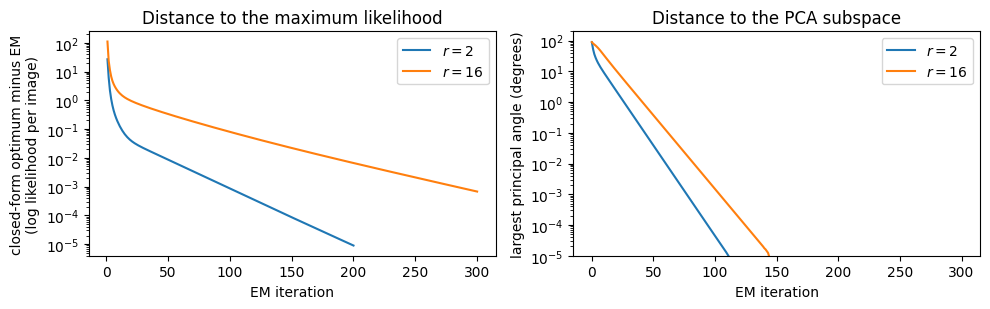

In [8]:
start = time.time()
W16, sigma2_16, trace16 = run_em(r=16, iterations=300)
print(f'300 EM iterations with r=16 took {time.time() - start:.2f}s')
W16_ml, sigma2_16_ml = closed_form(16)
print(f'eigenvalue gaps at the cut-off: lambda_2/lambda_3 = {eigenvalues[1] / eigenvalues[2]:.3f}, '
      f'lambda_16/lambda_17 = {eigenvalues[15] / eigenvalues[16]:.3f}')
print(f'r=16 sigma^2: EM {sigma2_16:.6f}   discarded-eigenvalue mean {sigma2_16_ml:.6f}')
print(f'r=16 log likelihood: EM {log_likelihood(W16, sigma2_16):.3f}   '
      f'closed form {log_likelihood(W16_ml, sigma2_16_ml):.3f}')
print(f'r=16 largest principal angle after 300 iterations: {trace16["angle"].iloc[-1]:.3f} degrees')

fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for trace, r, ml in [(trace2, 2, log_likelihood(W2_ml, sigma2_2_ml)),
                     (trace16, 16, log_likelihood(W16_ml, sigma2_16_ml))]:
    axes[0].plot(trace['iteration'][1:], ml - trace['log likelihood'][1:], label=f'$r={r}$')
    axes[1].plot(trace['iteration'], trace['angle'], label=f'$r={r}$')
axes[0].set(xlabel='EM iteration', ylabel='closed-form optimum minus EM\n(log likelihood per image)',
            yscale='log', title='Distance to the maximum likelihood')
axes[1].set(xlabel='EM iteration', ylabel='largest principal angle (degrees)', yscale='log', ylim=(1e-5, 200),
            title='Distance to the PCA subspace')
for ax in axes:
    ax.legend()
plt.tight_layout(); plt.show()
assert np.all(np.diff(trace16['log likelihood']) > -1e-9)
assert trace16['angle'].iloc[-1] < 1.0 and abs(sigma2_16 - sigma2_16_ml) / sigma2_16_ml < 1e-3

With $r=16$ the log likelihood again rises monotonically to 258.766
per image, against the closed-form optimum 258.767. The left panel shows the shortfall from the optimum shrinking
geometrically (a straight line on the log scale), and the right panel shows
the largest principal angle falling below $10^{-5}$ degrees. $\sigma^2$ again
equals the average of the discarded eigenvalues, 0.027838.

Both curves are straight lines on the log scale: EM is a fixed-point
iteration and converges at a geometric rate. The likelihood shortfall for
$r=16$ decays more slowly than for $r=2$, so the plane is found quickly in
both cases while the spread inside the larger subspace takes longer. (Below
about $10^{-5}$ degrees the angle curve is rounding noise.) This is the
Lecture 16 algorithm, unchanged, on a continuous hidden variable whose
posterior happens to stay Gaussian.

## 5. What a linear code does to images

Two quantities from the slides can now be read off the MNIST fit with
$r=16$. First the **shrinkage** of Appendix A.3: for the closed-form
$\widehat W$ (orthogonal columns $a_ju_j$ with $a_j^2=\lambda_j-\sigma^2$) the
posterior mean is the PCA score times $a_j/(a_j^2+\sigma^2)=a_j/\lambda_j$,
and the posterior variance of coordinate $j$ is $\sigma^2/\lambda_j$. Second,
the images: we reconstruct ten **test** digits from their posterior means,
$\mu+Wm_i$, and we generate ten new images by drawing $z\sim\mathcal N(0,I)$,
computing the decoder mean $\mu+Wz$, and adding the pixel noise
$\epsilon\sim\mathcal N(0,\sigma^2I)$ that the model also specifies.

Look at which of the three rows of generated or rebuilt images look like
handwriting.

posterior-mean factor a_j/(a_j^2+sigma^2) times a_j, for j = 1, 2, 8, 16: [0.9945 0.9925 0.9818 0.9647]
posterior standard deviation sqrt(sigma^2/lambda_j), j = 1, 2, 8, 16: [0.0741 0.0866 0.135  0.1878]


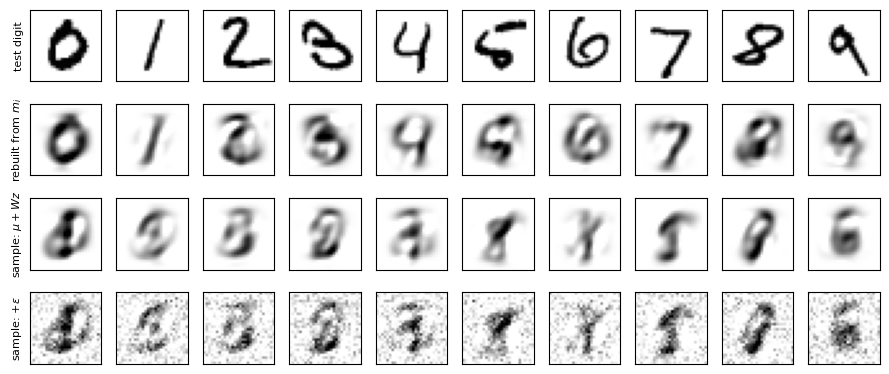

average squared reconstruction error on these ten test digits: 26.0 (the average squared norm of a centred digit is 55.9)


In [9]:
a = np.sqrt(eigenvalues[:16] - sigma2_16_ml)
shrink = a / (a ** 2 + sigma2_16_ml)
print('posterior-mean factor a_j/(a_j^2+sigma^2) times a_j, for j = 1, 2, 8, 16:',
      np.round((shrink * a)[[0, 1, 7, 15]], 4))
print('posterior standard deviation sqrt(sigma^2/lambda_j), j = 1, 2, 8, 16:',
      np.round(np.sqrt(sigma2_16_ml / eigenvalues[[0, 1, 7, 15]]), 4))

def posterior_mean(W, sigma2, images):
    M = W.T @ W + sigma2 * np.eye(W.shape[1])
    return (images - mu_hat) @ W @ np.linalg.inv(M)

test_digits = X_test[[int(np.where(labels_test == k)[0][0]) for k in range(10)]]
rebuilt = mu_hat + posterior_mean(W16, sigma2_16, test_digits) @ W16.T
sample_rng = np.random.default_rng(SEED + 2)
z_new = sample_rng.normal(size=(10, 16))
decoder_mean = mu_hat + z_new @ W16.T
with_noise = decoder_mean + sample_rng.normal(scale=np.sqrt(sigma2_16), size=decoder_mean.shape)

rows = [('test digit', test_digits), ('rebuilt from $m_i$', rebuilt),
        ('sample: $\\mu+Wz$', decoder_mean), ('sample: $+\\epsilon$', with_noise)]
fig, axes = plt.subplots(4, 10, figsize=(9, 4))
for row, (name, images) in enumerate(rows):
    for col in range(10):
        axes[row, col].imshow(images[col].reshape(28, 28), cmap='gray_r', vmin=0, vmax=1)
        axes[row, col].set_xticks([]); axes[row, col].set_yticks([])
    axes[row, 0].set_ylabel(name, fontsize=8)
plt.tight_layout(); plt.show()
error = np.mean(np.sum((rebuilt - test_digits) ** 2, axis=1))
print(f'average squared reconstruction error on these ten test digits: {error:.1f} '
      f'(the average squared norm of a centred digit is {np.mean(np.sum((test_digits - mu_hat) ** 2, axis=1)):.1f})')

The factor multiplying the standardized PCA score is 0.9945, 0.9925,
0.9818, and 0.9647 for $j=1,2,8,16$: close to 1 for the leading directions, where the signal dwarfs
$\sigma^2\approx0.04$, and smaller near the cut-off. The posterior standard
deviations, 0.074, 0.087, 0.135, and 0.188 (against a prior standard
deviation of 1), say how much of each coordinate the image leaves
undetermined.

The pictures show the limits of a linear decoder. Reconstructions through a
16-number code are recognizable but smeared, with grey ghost strokes from
other digits; the squared error, 26.0, is about half of the 55.9 that a
centred test digit carries. Samples from
the prior are worse: $\mu+Wz$ is a smooth blend of strokes that rarely forms
a single digit, and adding the model's own pixel noise produces static. The
fitted model is a single Gaussian over $\mathbb R^{784}$, and a Gaussian
cloud cannot concentrate on the curved, thin set of images that look like
handwriting. Making the decoder nonlinear is the fix, and it is what costs
us the closed-form posterior.

## 6. The same model as a linear VAE

Now forget the closed-form E-step and train PPCA the way a VAE is trained.
The **decoder** is the PPCA likelihood $p_\theta(x\mid z)=\mathcal
N(Wz+\mu,\sigma^2I)$ with learnable $W$ and $\log\sigma^2$. The **encoder** is
the linear Gaussian family of the slide *A Linear $q_\phi$ Gives PPCA*,

$$q_\phi(z\mid x)=\mathcal N\bigl(A(x-\mu),\;\Sigma_q\bigr),\qquad \phi=(A,\Sigma_q),$$

with $\Sigma_q=LL^\top$ for a learnable lower-triangular $L$ with positive
diagonal. We maximize the ELBO

$$\mathcal L=\mathbb E_{q_\phi}\bigl[\log p_\theta(x\mid z)\bigr]-D_{\rm KL}\bigl(q_\phi(z\mid x)\,\|\,\mathcal N(0,I)\bigr)$$

by Adam on minibatches, estimating the first term with **one
reparameterized draw** $z=A(x-\mu)+L\varepsilon$ per image and using the
closed-form Gaussian KL,
$\tfrac12\bigl[\operatorname{tr}\Sigma_q+\|m\|^2-r-\log\det\Sigma_q\bigr]$.

For evaluation we do not need sampling: with a linear decoder the expected
squared error is exactly $\|x-\mu-Wm\|^2+\operatorname{tr}(W\Sigma_qW^\top)$,
so the ELBO can be computed in closed form and compared with the exact log
likelihood $\log p_\theta(x)$ from Section 4. Their difference is the gap
$D_{\rm KL}(q_\phi\,\|\,p_\theta(z\mid x))\ge0$.

The cell defines the model and the two ELBOs, then trains with $r=16$ on
the same 10,000 centred images for 60 epochs of batches of 100, with Adam
at learning rate $0.003$ decaying to zero along a cosine. Look at
the printed ELBO, log likelihood, and gap as training proceeds.

In [10]:
class LinearVAE(nn.Module):
    """PPCA decoder N(Wz + mu, sigma^2 I) with a linear Gaussian encoder N(A(x - mu), L L^T)."""
    def __init__(self, d, r):
        super().__init__()
        self.W = nn.Parameter(torch.randn(d, r) / d ** .5)
        self.log_sigma2 = nn.Parameter(torch.tensor(np.log(np.trace(Sigma_hat) / d)))
        self.A = nn.Parameter(torch.zeros(r, d))
        self.L_raw = nn.Parameter(torch.zeros(r, r))       # strictly lower part + log diagonal

    def L(self):
        return torch.tril(self.L_raw, -1) + torch.diag(torch.exp(torch.diagonal(self.L_raw)))

    def kl(self, m):
        L = self.L(); r = m.shape[1]
        log_det = 2 * torch.log(torch.diagonal(L)).sum()
        return .5 * ((L ** 2).sum() + (m ** 2).sum(1) - r - log_det)

    def sampled_elbo(self, xc):
        """One reparameterized draw per image: what the training loop optimizes."""
        m = xc @ self.A.T
        z = m + torch.randn_like(m) @ self.L().T
        sigma2 = torch.exp(self.log_sigma2)
        log_lik = -.5 * (d * torch.log(2 * np.pi * sigma2) + ((xc - z @ self.W.T) ** 2).sum(1) / sigma2)
        return log_lik - self.kl(m)

    def exact_elbo(self, xc):
        """Same objective with the expectation over q done in closed form (linear decoder only)."""
        m = xc @ self.A.T
        L = self.L(); sigma2 = torch.exp(self.log_sigma2)
        expected_sq = ((xc - m @ self.W.T) ** 2).sum(1) + ((self.W @ L) ** 2).sum()
        log_lik = -.5 * (d * torch.log(2 * np.pi * sigma2) + expected_sq / sigma2)
        return log_lik - self.kl(m)

torch.manual_seed(SEED)
Xc_t = torch.tensor(Xc)                                   # float64 keeps the gap measurable
vae = LinearVAE(d, 16).double()
optimizer = torch.optim.Adam(vae.parameters(), lr=3e-3)
EPOCHS, BATCH = 60, 100
# The learning rate decays to zero along a cosine, so the minibatch noise dies out at the end.
schedule = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS * (n // BATCH))
generator = torch.Generator().manual_seed(SEED)

def report(epoch):
    with torch.no_grad():
        elbo = vae.exact_elbo(Xc_t).mean().item()
        W_np, s2 = vae.W.numpy(), float(torch.exp(vae.log_sigma2))
    ll = log_likelihood(W_np, s2)
    return {'epoch': epoch, 'ELBO': elbo, 'log p(x)': ll, 'gap': ll - elbo,
            'angle to PCA': largest_angle(W_np, eigenvectors[:, :16]), 'sigma2': s2}

history = [report(0)]
start = time.time()
for epoch in range(1, EPOCHS + 1):
    order = torch.randperm(n, generator=generator)
    for first in range(0, n, BATCH):
        batch = Xc_t[order[first:first + BATCH]]
        loss = -vae.sampled_elbo(batch).mean()     # one reparameterized draw per image
        optimizer.zero_grad(); loss.backward(); optimizer.step(); schedule.step()
    if epoch in (1, 2, 5, 10, 20, 40, 60):
        history.append(report(epoch))
print(f'training took {time.time() - start:.1f}s')
history = pd.DataFrame(history)
display(history.round(4))

training took 12.5s


,epoch,ELBO,log p(x),gap,angle to PCA,sigma2
0,0,-171.6247,-68.5714,103.0533,89.3652,0.0672
1,1,146.3496,169.9037,23.5540,62.4834,0.0529
2,2,200.4036,218.7226,18.3190,36.6432,0.0398
3,5,240.5794,248.9488,8.3694,10.6938,0.0299
4,10,252.5781,255.3089,2.7308,6.9540,0.0286
5,20,255.3483,256.8767,1.5284,5.6715,0.0283
6,40,257.9718,258.4258,0.4541,2.2655,0.0280
7,60,258.7120,258.7415,0.0295,0.2202,0.0279


At the random start the ELBO is $-171.6$ per image, 103 nats below the
log likelihood of the same parameters: the encoder ($A=0$, $\Sigma_q=I$)
ignores the image, so $q_\phi$ is far from the posterior. Training raises
both curves, and the gap closes from 103 to 0.03 nats while the largest
principal angle between $\mathrm{col}(W)$ and the PCA subspace falls from
$89.4^\circ$ to $0.22^\circ$ and $\sigma^2$ falls from 0.067 to 0.0279. The
gap shrinks fastest at the end, when the decaying learning rate removes the
minibatch noise. No E-step formula appears anywhere in the training loop;
the encoder found the posterior by gradient ascent on the ELBO.

The gap is the KL divergence from $q_\phi$ to the true posterior, so
it is small only if the encoder has learned the E-step. The cell compares
the learned encoder with the exact posterior of the learned decoder,
$A^\star=M^{-1}W^\top$ and $S=\sigma^2M^{-1}$, and the learned decoder with
the closed-form maximum-likelihood solution.

In [11]:
with torch.no_grad():
    W_v, s2_v = vae.W.numpy(), float(torch.exp(vae.log_sigma2))
    A_v = vae.A.numpy(); Sq_v = (vae.L() @ vae.L().T).numpy()
M_v = W_v.T @ W_v + s2_v * np.eye(16)
A_star = np.linalg.solve(M_v, W_v.T)
S_star = s2_v * np.linalg.inv(M_v)
# Compare the encoder means on the data: directions in which no image varies
# (115 pixels are always zero) receive no gradient and do not matter.
print(f'encoder means on the data: ||Xc (A - M^-1 W^T)^T|| / ||Xc (M^-1 W^T)^T|| = '
      f'{np.linalg.norm(Xc @ (A_v - A_star).T) / np.linalg.norm(Xc @ A_star.T):.4f}')
print(f'encoder covariance: ||Sigma_q - sigma^2 M^-1|| / ||sigma^2 M^-1|| = '
      f'{np.linalg.norm(Sq_v - S_star) / np.linalg.norm(S_star):.3f}')
print(f'sigma^2: linear VAE {s2_v:.5f}   closed-form ML {sigma2_16_ml:.5f}')
print(f'log likelihood per image: linear VAE {log_likelihood(W_v, s2_v):.3f}   '
      f'closed-form ML {log_likelihood(W16_ml, sigma2_16_ml):.3f}')
print(f'largest principal angle, col(W_VAE) vs PCA: {largest_angle(W_v, eigenvectors[:, :16]):.2f} degrees')
final = history.iloc[-1]
assert 0 <= final['gap'] < 0.2 and final['angle to PCA'] < 1.0

encoder means on the data: ||Xc (A - M^-1 W^T)^T|| / ||Xc (M^-1 W^T)^T|| = 0.0079
encoder covariance: ||Sigma_q - sigma^2 M^-1|| / ||sigma^2 M^-1|| = 0.016
sigma^2: linear VAE 0.02786   closed-form ML 0.02784
log likelihood per image: linear VAE 258.742   closed-form ML 258.767
largest principal angle, col(W_VAE) vs PCA: 0.22 degrees


On the data, the learned encoder means agree with the exact posterior
means $M^{-1}W^\top(x_i-\bar x)$ to 0.8%, and $\Sigma_q$ agrees with
$S=\sigma^2M^{-1}$ to 1.6%. The decoder matches the closed-form maximum
likelihood: $\sigma^2=0.02786$ against 0.02784, a log likelihood of 258.742
against 258.767 per image, and a subspace within $0.22^\circ$ of PCA's.
This is the claim of the slide *A Linear $q_\phi$ Gives PPCA*: the linear
Gaussian family contains the exact posterior, so maximizing the ELBO over
$\phi$ reproduces the E-step, and maximizing it over $\theta$ reproduces the
M-step, both at once and by stochastic gradients.

## 7. When the decoder is a network

Everything that made Sections 3 and 4 work was linear algebra: the
posterior was Gaussian, $\log p_\theta(x)$ was a Gaussian log density, and
the gap could be computed exactly. Replace $Wz+\mu$ by a network
$f_\theta(z)$ and all three disappear. The ELBO can still be estimated, with
one draw per image, and $\log p_\theta(x)$ can only be estimated by Monte
Carlo, for example by **importance sampling** with the encoder as proposal:

$$\log p_\theta(x)\approx\log\frac1K\sum_{k=1}^K\frac{p(z_k)\,p_\theta(x\mid z_k)}{q_\phi(z_k\mid x)},\qquad z_k\sim q_\phi(\cdot\mid x).$$

Each term in the average has expectation $p_\theta(x)$, and by Jensen the
estimate is a lower bound in expectation that tightens as $K$ grows; $K=1$
is the ELBO itself. The linear VAE lets us check this tool against the
truth before trusting it on a network. The cell evaluates the estimate on
500 test images for $K=1$, 10, 100, and 1,000, and compares with the exact
Gaussian log likelihood of the same images.

In [12]:
torch.manual_seed(SEED + 3)
test_c = torch.tensor(X_test[:500] - mu_hat)
with torch.no_grad():
    L_v = vae.L(); sigma2 = torch.exp(vae.log_sigma2)
    m = test_c @ vae.A.T
    log_det_q = 2 * torch.log(torch.diagonal(L_v)).sum()
    estimates = {}
    for K in (1, 10, 100, 1000):
        eps = torch.randn(K, *m.shape, dtype=m.dtype)
        z = m + eps @ L_v.T                                             # K x 500 x r
        log_prior = -.5 * (z ** 2).sum(-1) - 8 * np.log(2 * np.pi)
        log_lik = -.5 * (d * torch.log(2 * np.pi * sigma2)
                         + ((test_c - z @ vae.W.T) ** 2).sum(-1) / sigma2)
        log_q = -.5 * (eps ** 2).sum(-1) - 8 * np.log(2 * np.pi) - .5 * log_det_q
        log_w = log_prior + log_lik - log_q
        estimates[K] = (torch.logsumexp(log_w, 0) - np.log(K)).mean().item()
test_Sigma = test_c.numpy().T @ test_c.numpy() / 500
exact_test = log_likelihood(W_v, s2_v, Sigma=test_Sigma)
for K, value in estimates.items():
    print(f'K = {K:4d}: importance-sampling estimate {value:9.3f}')
print(f'exact log likelihood of the same 500 test images: {exact_test:9.3f}')
assert abs(estimates[1000] - exact_test) < 1.0

K =    1: importance-sampling estimate   266.602
K =   10: importance-sampling estimate   266.620
K =  100: importance-sampling estimate   266.619
K = 1000: importance-sampling estimate   266.622
exact log likelihood of the same 500 test images:   266.621


All four estimates lie between 266.602 and 266.622 against the exact
value 266.621, and the $K=1$ estimate is the ELBO of the test images, 0.02
nats below. The curve is flat in $K$ for a reason: when $q_\phi$ equals the
posterior, every importance weight $p(z_k)p_\theta(x\mid z_k)/q_\phi(z_k\mid
x)$ equals $p_\theta(x)$ exactly, so a single draw already gives the answer.
With a network decoder the encoder can only approximate the posterior, the
weights vary from draw to draw, and the estimate climbs with $K$ towards
$\log p_\theta(x)$ from below. The `vae-mnist` notebook measures exactly
that climb.

## Summary

Probabilistic PCA is the latent-variable model in which every step of
Lecture 16 survives a continuous code. On a toy example the first principal
direction of a noisy cloud sits within $0.02^\circ$ of $\mathrm{col}(W)$,
because the covariance $WW^\top+\sigma^2I$ has eigenvalue $a_j^2+\sigma^2$
along the loadings and $\sigma^2$ elsewhere. The posterior is a closed-form
Gaussian whose covariance $S=\sigma^2M^{-1}$ is shared by every observation,
and its mean is the PCA score shrunk by a factor between 0.96 and 0.99 on
MNIST. EM on 10,000 MNIST images increases the log likelihood at every
iteration, rotates $\mathrm{col}(W)$ onto the top-$r$ eigenvectors, and sets
$\sigma^2$ to the average discarded eigenvalue (0.056 for $r=2$, 0.028 for
$r=16$); the individual columns of $W$ are an arbitrary rotation of the
eigenvectors. A linear decoder produces smeared reconstructions and samples
that are blends of strokes. Trained instead as a linear VAE, with one
reparameterized draw per image and no E-step formula, the same model
reaches the maximum-likelihood fit to 0.03 nats, its encoder reproduces the
exact posterior to about 1%, and the ELBO gap closes. A network decoder
removes the closed forms used here, and importance sampling is the tool
that remains for measuring $\log p_\theta(x)$.

## Try It

For each change, write down a prediction before rerunning the cells.

1. **A large start.** In `run_em`, replace `scale=1 / np.sqrt(d)` by
   `scale=1.0`, so each column of $W$ starts with length about 28. Predict
   how many iterations $r=2$ now needs to reach the closed-form likelihood.
   (In one direction with sample variance $\lambda$, a column with
   $a^2\gg\lambda$ shrinks by about $\lambda/(\lambda+\sigma^2)\approx0.99$
   per iteration.)
2. **The size of the code.** Use `closed_form(r)` and `log_likelihood` to
   compute the training log likelihood per image for $r=1,2,4,\dots,256$,
   and the same quantity on the test images (pass
   `Sigma=` the test covariance about `mu_hat`). Does the held-out value
   keep rising with $r$?
3. **A diagonal encoder.** In `LinearVAE`, keep only the diagonal of `L`.
   The exact posterior covariance $\sigma^2M^{-1}$ is diagonal only when the
   columns of $W$ are orthogonal. Predict whether the gap still closes, and
   what the training does to the columns of $W$ instead.
4. **No uncertainty in the M-step.** In `m_step`, drop the `n * S` term, so
   the M-step treats $m_i$ as if it were the true code. Predict what happens
   to $\sigma^2$ and to the likelihood; check whether EM is still monotone.
5. **Fewer importance samples.** Rerun Section 7 with 50 test images and
   $K=10{,}000$. Does the estimate reach the exact value, and how does the
   spread across repeated runs change with $K$?

In [13]:
print(f'notebook ran in {time.time() - NOTEBOOK_START:.0f}s')

notebook ran in 33s
